# Cloud masking vs real cloud changes (APRP)

**Question (user 2026-11-24).** The Ghan cloud term, SW_cloud = FSNT_DRF − FSNTCDRF, changes when the clouds change (**real change**) but also when only what is under the clouds changes (**cloud masking**): a darker surface raises the clear-sky absorbed SW much more than the all-sky one, so the cloud term goes negative with identical clouds. How much of the SW cloud term of the forcing tree is masking?

**Method 1 — APRP** (Approximate Partial Radiative Perturbation, Taylor et al. 2007, *J. Climate* 20, 3637), §1–3. Month by month and cell by cell, a single-layer model is fitted to the clear-sky and the overcast column. The change of absorbed SW is split into surface albedo, cloud amount, cloud scattering, cloud absorption and non-cloud atmosphere, once for all-sky and once for clear-sky. Then, exactly:

$$\Delta\,\text{cloud term} = \underbrace{\text{cloud amount + scattering + absorption}}_{\text{real cloud change}} + \underbrace{(\text{sfc}_\text{all} - \text{sfc}_\text{clr})}_{\text{surface-albedo masking}} + \underbrace{(\text{atm}_\text{all} - \text{atm}_\text{clr})}_{\text{atmosphere masking}} + \text{residual}$$

APRP is run on the **clean** (aerosol-free) radiation calls, the same basis as the Ghan cloud term, and, for comparison, on the standard all-sky fluxes (which include aerosols, so their cloud term is SWCF-like, not Ghan).

**Method 2 — look at the clouds themselves**, §4: maps of cloud fraction, liquid/ice water path, droplet number and cloud-top droplet radius next to the cloud terms, and spatial correlations. A cloud term with no change in the clouds points to masking.

**Contrasts** = the pairs of the forcing tree (`analysis/radiative_forcing_tree.py`, user 2026-11-23/24): for each case, total T, non-BVOC N (same prescribed emissions in both runs) and BVOC B (`LCC_P_fBVOClccP` − `LCC_P_fBVOC<E>`, design A). Years 2001–2025 (25 nudged years), means ≥45°N and over the modified cells, ± 95 % t-interval of the yearly means; hatching = not significant (FDR).

**Caveats.** SW only (LW masking needs radiative kernels, not on Betzy). Monthly-mean APRP: sub-monthly co-variation of clouds and insolation is not resolved. Cloud fraction = CLDTOT (random-overlap total); columns with CLDTOT < 2 % are treated as clear. The clean clear-sky surface upward flux is not in the output: it is built from the clear-sky surface albedo (aerosols hardly change the surface albedo, (b)). Nudged runs with fixed SST and sea ice: the cloud changes include fast responses.

**Outputs.** Figures `results/figures/cloud-masking-aprp/`, tables `results/tables/cloud-masking-aprp/`, yearly-term cache `analysis/cloud-masking-aprp_outputs/cache/` (→ `/cluster/work`, regenerable).

In [1]:
import sys
import time
from functools import lru_cache
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

REPO = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from boreal_forest_expansion.analysis.regions import load_modified_cells  # noqa: E402
from boreal_forest_expansion.plotting import forcing_maps as fm  # noqa: E402
from boreal_forest_expansion.plotting.style import set_default_style  # noqa: E402

set_default_style()
STEM = "cloud-masking-aprp"
FIGDIR, TABDIR = fm.set_output_notebook(STEM)
CACHE = REPO / "analysis" / f"{STEM}_outputs" / "cache"   # symlink to /cluster/work/users/adelez/boreal-caches/...
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
Y0, Y1, LAT_MIN = 2001, 2040, 45

# Forcing-tree cases (analysis/radiative_forcing_tree.py): T = total, N = non-BVOC, B = BVOC, as (case1, case2)
CASES = {
    "LCCPD_fBVOCctrlPD": dict(title="[LCC − CTRL] _PD", T=("LCC_PD", "CTRL_PD"),
                              N=("LCC_PD_fBVOCctrlPD", "CTRL_PD_fBVOCctrlPD"), B=("LCC_PD_fBVOClccPD", "LCC_PD_fBVOCctrlPD")),
    "LCCFUT_fBVOCctrlFUT": dict(title="[LCC − CTRL] _FUT", T=("LCC_FUT", "CTRL_FUT"),
                                N=("LCC_FUT_fBVOCctrlFUT", "CTRL_FUT_fBVOCctrlFUT"), B=("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlFUT")),
    "LCCFUT_fBVOClccPD": dict(title="LCC_FUT − LCC_PD", T=("LCC_FUT", "LCC_PD"),
                              N=("LCC_FUT_fBVOClccPD", "LCC_PD_fBVOClccPD"), B=("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOClccPD")),
    "LCCFUT_fBVOCctrlPD": dict(title="LCC_FUT − CTRL_PD", T=("LCC_FUT", "CTRL_PD"),
                               N=("LCC_FUT_fBVOCctrlPD", "CTRL_PD_fBVOCctrlPD"), B=("LCC_FUT_fBVOClccFUT", "LCC_FUT_fBVOCctrlPD")),
}
BRANCH = {"T": "TOTAL", "N": "NON-BVOC", "B": "BVOC"}
PAIRS = list(dict.fromkeys(case[k] for case in CASES.values() for k in "TNB"))
print(len(PAIRS), "pairs:", *[f"{a} − {b}" for a, b in PAIRS], sep="\n  ")

12
  pairs:
  LCC_PD − CTRL_PD
  LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD
  LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD
  LCC_FUT − CTRL_FUT
  LCC_FUT_fBVOCctrlFUT − CTRL_FUT_fBVOCctrlFUT
  LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlFUT
  LCC_FUT − LCC_PD
  LCC_FUT_fBVOClccPD − LCC_PD_fBVOClccPD
  LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOClccPD
  LCC_FUT − CTRL_PD
  LCC_FUT_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD
  LCC_FUT_fBVOClccFUT − LCC_FUT_fBVOCctrlPD


## 1. APRP

Per run and month: insolation S, upward TOA flux (all-sky, clear-sky), downward and upward surface flux (all-sky, clear-sky), cloud fraction c. Overcast fluxes: F_oc = (F − (1 − c) F_clr) / c. For the clear and the overcast column, with α = upward TOA / S, Q̂ = downward surface / S and surface albedo a:

μ = α + Q̂ (1 − a) (1 − atmospheric absorption), γ = (μ − Q̂) / (μ − a Q̂) (atmospheric reflectance), A(μ, γ, a) = μγ + μ a (1 − γ)² / (1 − a γ).

Cloud = overcast relative to clear: μ_oc = μ_clr μ_cld, 1 − γ_oc = (1 − γ_clr)(1 − γ_cld). All-sky A = (1 − c) A_clr + c A_oc. Each term = −S̄ × (centred partial change of A), swapping one group of parameters forward from the reference run and backward from the new run: surface albedo (a_clr, a_oc), cloud amount (c), cloud scattering (γ_cld), cloud absorption (μ_cld), non-cloud atmosphere (μ_clr, γ_clr). Clear-sky terms use A_clr only. Insolation change term = ΔS (1 − Ā) (non-zero only between PD and FUT orbits). Residual = actual change − sum of terms (non-linearity).

In [2]:
# --- APRP (Taylor et al. 2007, J. Climate 20, 3637), monthly, per grid cell -------------------------
# Single-layer model of one column: mu = 1 - atmospheric absorption, gam = atmospheric reflectance,
# a = surface albedo. Planetary albedo A = mu*gam + mu*a*(1-gam)^2 / (1 - a*gam).
# Clear and overcast columns are inverted separately; the cloud = overcast relative to clear:
# mu_oc = mu_clr*mu_cld, 1 - gam_oc = (1 - gam_clr)(1 - gam_cld). All-sky A = (1-c) A_clr + c A_oc.
C_MIN = 0.02   # cloud fraction below which the column is treated as clear (overcast fluxes undefined)
S_MIN = 1.0    # W m-2: insolation below which a month carries no SW (polar night)

# Upward/downward SW fluxes per flux set. "clean" = aerosol-free radiation calls (_DRF, the Ghan basis);
# the clean clear-sky TOA upward flux adds the above-model-top absorption of the clear-sky call
# (FSNTOAC - FSNTC) to FSNTCDRF, and the clean clear-sky surface upward flux uses the clear-sky
# surface albedo (FSDSC - FSNSC) / FSDSC (no clean clear-sky surface upward flux in the output).
FLUX_SETS = {
    "clean": dict(rsut=lambda d: d.FSUTADRF,
                  rsutcs=lambda d: d.SOLIN - d.FSNTCDRF - (d.FSNTOAC - d.FSNTC),
                  rsds=lambda d: d.FSDS_DRF, rsus=lambda d: d.FSUS_DRF,
                  rsdscs=lambda d: d.FSDSCDRF,
                  rsuscs=lambda d: d.FSDSCDRF * ((d.FSDSC - d.FSNSC) / d.FSDSC.where(d.FSDSC > S_MIN)).fillna(0)),
    "allsky": dict(rsut=lambda d: d.SOLIN - d.FSNTOA, rsutcs=lambda d: d.SOLIN - d.FSNTOAC,
                   rsds=lambda d: d.FSDS, rsus=lambda d: d.FSDS - d.FSNS,
                   rsdscs=lambda d: d.FSDSC, rsuscs=lambda d: d.FSDSC - d.FSNSC),
}
APRP_VARS = ["SOLIN", "FSNTOA", "FSNTOAC", "FSNTC", "FSNTCDRF", "FSNT_DRF", "FSUTADRF", "FSDS", "FSNS",
             "FSDSC", "FSNSC", "FSDS_DRF", "FSUS_DRF", "FSDSCDRF", "SW_cloud"]


def _ratio(a, b, fill):
    ok = np.abs(b) > 1e-6
    return np.where(ok, a / np.where(ok, b, 1.0), fill)


def _mu_gam(alpha, qhat, a):
    mu = alpha + qhat * (1 - a)
    return mu, _ratio(mu - qhat, mu - a * qhat, 0.0)


def aprp_params(d, fs):
    """APRP parameters of one run (numpy, time x lat x lon) + insolation and upward TOA flux."""
    f = {k: np.asarray(v(d).values, dtype="float64") for k, v in FLUX_SETS[fs].items()}
    S = np.asarray(d.SOLIN.values, dtype="float64")
    c = np.clip(np.asarray(d.CLDTOT.values, dtype="float64"), 0, 1)
    cloudy = c >= C_MIN
    cc = np.where(cloudy, c, 1.0)
    oc = {k: np.where(cloudy, (f[k] - (1 - c) * f[k + "cs"]) / cc, f[k + "cs"]) for k in ("rsut", "rsds", "rsus")}
    a_clr = np.clip(_ratio(f["rsuscs"], f["rsdscs"], 0.0), 0, 0.999)
    a_oc = np.clip(np.where(oc["rsds"] > S_MIN, _ratio(oc["rsus"], oc["rsds"], 0.0), a_clr), 0, 0.999)
    Sx = np.where(S > S_MIN, S, 1.0)
    mu_clr, gam_clr = _mu_gam(f["rsutcs"] / Sx, f["rsdscs"] / Sx, a_clr)
    mu_oc, gam_oc = _mu_gam(oc["rsut"] / Sx, oc["rsds"] / Sx, a_oc)
    p = dict(c=np.where(cloudy, c, 0.0), a_clr=a_clr, a_oc=a_oc, mu_clr=mu_clr, gam_clr=gam_clr,
             mu_cld=np.where(cloudy, _ratio(mu_oc, mu_clr, 1.0), 1.0),
             gam_cld=np.where(cloudy, 1 - _ratio(1 - gam_oc, 1 - gam_clr, 1.0), 0.0))
    return p, S, f["rsut"], f["rsutcs"]


def _A1(mu, gam, a):
    return mu * gam + mu * a * (1 - gam) ** 2 / (1 - a * gam)


def albedo_all(p):
    A_oc = _A1(p["mu_clr"] * p["mu_cld"], 1 - (1 - p["gam_clr"]) * (1 - p["gam_cld"]), p["a_oc"])
    return (1 - p["c"]) * _A1(p["mu_clr"], p["gam_clr"], p["a_clr"]) + p["c"] * A_oc


def albedo_clr(p):
    return _A1(p["mu_clr"], p["gam_clr"], p["a_clr"])


def dA(fun, p_ref, p_new, keys):
    """Centred partial albedo change: swap `keys` forward from the reference and backward from the new state."""
    swap = lambda p, q: {**p, **{k: q[k] for k in keys}}
    return 0.5 * ((fun(swap(p_ref, p_new)) - fun(p_ref)) + (fun(p_new) - fun(swap(p_new, p_ref))))


TERMS_ALL = {"sfc_all": ("a_clr", "a_oc"), "cld_amt": ("c",), "cld_scat": ("gam_cld",),
             "cld_abs": ("mu_cld",), "atm_all": ("mu_clr", "gam_clr")}
TERMS_CLR = {"sfc_clr": ("a_clr",), "atm_clr": ("mu_clr", "gam_clr")}


def aprp_monthly(d_new, d_ref, fs):
    """Monthly APRP terms of d_new - d_ref (W m-2, + = more SW absorbed), dict of numpy arrays."""
    p1, S1, up1, upc1 = aprp_params(d_ref, fs)
    p2, S2, up2, upc2 = aprp_params(d_new, fs)
    lit = (S1 > S_MIN) & (S2 > S_MIN)
    Sm, dS = 0.5 * (S1 + S2), S2 - S1
    out = {}
    for fun, terms, sfx, upa, upb in ((albedo_all, TERMS_ALL, "all", up1, up2), (albedo_clr, TERMS_CLR, "clr", upc1, upc2)):
        for name, keys in terms.items():
            out[name] = np.where(lit, -Sm * dA(fun, p1, p2, keys), 0.0)
        # actual change of the absorbed SW and its exact split -S̄ ΔA + ΔS (1 - Ā)
        A1, A2 = _ratio(upa, S1, 0.0), _ratio(upb, S2, 0.0)
        out[f"dF_{sfx}"] = np.where(lit, (S2 - upb) - (S1 - upa), 0.0)
        out[f"ins_{sfx}"] = np.where(lit, dS * (1 - 0.5 * (A1 + A2)), 0.0)
        out[f"recon_{sfx}"] = np.where(lit, np.abs(fun(p1) - A1) + np.abs(fun(p2) - A2), 0.0)   # model inversion check
    for sfx, terms in (("all", TERMS_ALL), ("clr", TERMS_CLR)):
        out[f"res_{sfx}"] = out[f"dF_{sfx}"] - out[f"ins_{sfx}"] - sum(out[k] for k in terms)
    return out


@lru_cache(maxsize=3)
def read_run(alias):
    # Monthly SW fluxes + CLDTOT of one run (2001–2025); a few retries for NIRD read errors
    for attempt in range(1, 6):
        try:
            r = fm.open_class(alias, "RADIATIVE", Y0, Y1)
            bnds = [v for v in r.variables if "bnds" in v or "bounds" in v]
            c = fm.open_class(alias, "CLOUDPROP", Y0, Y1)[["CLDTOT"]]
            ds = xr.merge([r[APRP_VARS + bnds], c]).load()
            break
        except (RuntimeError, OSError) as exc:
            print(f"{alias}: read failed ({attempt}/5): {exc}")
            if attempt == 5:
                raise
            time.sleep(20 * attempt)
    ds.attrs["alias"] = alias
    return ds


def aprp_pair(case1, case2, fs):
    # Yearly (year, lat, lon) APRP terms of case1 − case2 and the Ghan SW cloud term, cached
    path = CACHE / f"{case1}__{case2}_{fs}_{Y0}_{Y1}.nc"
    if path.exists() and not REBUILD_CACHE:
        return xr.load_dataset(path)
    d1, d2 = read_run(case1), read_run(case2)
    if not np.array_equal(d1["time"].values, d2["time"].values):
        raise ValueError(f"{case1} and {case2} have different time axes")
    o = aprp_monthly(d1, d2, fs)
    o["ghan_cloud"] = (d1["SW_cloud"] - d2["SW_cloud"]).values
    o["cloud"] = o["cld_amt"] + o["cld_scat"] + o["cld_abs"]
    o["mask_sfc"] = o["sfc_all"] - o["sfc_clr"]
    o["mask_atm"] = o["atm_all"] - o["atm_clr"]
    o["cre"] = o["dF_all"] - o["dF_clr"]                       # APRP-basis cloud term
    o["other"] = o["cre"] - o["cloud"] - o["mask_sfc"] - o["mask_atm"]   # residuals + insolation (small)
    o["mask_atm_other"] = o["mask_atm"] + o["other"]
    o["top_diff"] = o["ghan_cloud"] - o["cre"]                 # above-model-top absorption, clear-sky surface proxy
    dims, coords = d2["SOLIN"].dims, d2["SOLIN"].coords
    ds = xr.Dataset({k: fm.annual_mean(xr.DataArray(v, dims=dims, coords=coords), d2) for k, v in o.items()})
    ds = ds.astype("float32").assign_attrs(case1=case1, case2=case2, flux_set=fs, units="W m-2",
                                           sign="positive = more SW absorbed (warming)")
    ds.to_netcdf(path.with_suffix(".tmp"))
    path.with_suffix(".tmp").rename(path)
    return ds


t0 = time.time()
APRP = {(p, fs): aprp_pair(*p, fs) for p in PAIRS for fs in ("clean", "allsky")}
print(f"{len(APRP)} pair × flux-set results in {time.time() - t0:.0f} s")

24 pair × flux-set results in 26 s


## 2. Checks

- `recon`: the single-layer model must give back the actual planetary albedo of each run (clear-sky exact; all-sky off only where CLDTOT < 2 % is treated as clear).
- `res_all / dF_all`: APRP non-linearity, as a fraction of the actual all-sky change (≥45°N means).
- `ghan − cre` (clean only): the clean APRP cloud term vs the Ghan SW cloud term. They differ only by the above-model-top absorption and the clear-sky surface-albedo proxy; it must be small.

In [3]:
mod = load_modified_cells(fm.MODIFIED_CELLS, next(iter(APRP.values())))


def region_mean(d, region):
    # mean and 95 % half-width of the yearly regional means; region = '≥45°N' or 'modified cells'
    return fm.regional_mean_interval(d, lat_min=LAT_MIN) if region == "≥45°N" else fm.regional_mean_interval(d.where(mod))


rows = []
for (p, fs), ds in APRP.items():
    m = lambda k: region_mean(ds[k], "≥45°N")[0]
    rows.append(dict(pair=f"{p[0]} − {p[1]}", flux_set=fs, recon_all_max=float(ds["recon_all"].max()),
                     recon_clr_max=float(ds["recon_clr"].max()), dF_all=m("dF_all"), res_all=m("res_all"),
                     res_clr=m("res_clr"), ghan_cloud=m("ghan_cloud"), cre=m("cre"),
                     ghan_minus_cre_maxabs=float(abs(ds["top_diff"].mean("year")).where(ds["lat"] >= LAT_MIN).max())))
checks = pd.DataFrame(rows)
checks.to_csv(TABDIR / f"aprp_checks_{Y0}_{Y1}.csv", index=False)
pd.set_option("display.width", 250, "display.max_columns", 30)
checks.round(3)

,pair,flux_set,recon_all_max,recon_clr_max,dF_all,res_all,res_clr,ghan_cloud,cre,ghan_minus_cre_maxabs
0,LCC_PD − CTRL_PD,clean,0.003,0.0,0.349,0.000,0.0,-0.074,-0.074,0.002
1,LCC_PD − CTRL_PD,allsky,0.003,0.0,0.331,-0.000,-0.0,-0.074,-0.072,0.521
2,LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD,clean,0.003,0.0,0.378,-0.000,0.0,-0.060,-0.060,0.002
3,LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD,allsky,0.003,0.0,0.361,-0.000,0.0,-0.060,-0.061,0.529
4,LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD,clean,0.003,0.0,-0.035,0.000,0.0,-0.023,-0.023,0.000
5,LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD,allsky,0.003,0.0,-0.036,0.000,-0.0,-0.023,-0.020,0.053
6,LCC_FUT − CTRL_FUT,clean,0.003,0.0,0.267,-0.000,0.0,-0.052,-0.052,0.002
7,LCC_FUT − CTRL_FUT,allsky,0.003,0.0,0.260,-0.000,-0.0,-0.052,-0.054,0.274
8,LCC_FUT_fBVOCctrlFUT − CTRL_FUT_fBVOCctrlFUT,clean,0.003,0.0,0.319,-0.000,0.0,-0.009,-0.009,0.002
9,LCC_FUT_fBVOCctrlFUT − CTRL_FUT_fBVOCctrlFUT,allsky,0.003,0.0,0.307,-0.000,0.0,-0.009,-0.010,0.298


## 3. Results: how much of the SW cloud term is masking

Table: means ≥45°N and over the modified cells (W m⁻², ± 95 %), clean APRP unless `flux_set = allsky`. Columns: `ghan_cloud` = Ghan SW cloud term; `cloud` = real cloud change (= `cld_amt` + `cld_scat` + `cld_abs`); `mask_sfc` = surface-albedo masking; `mask_atm` = non-cloud-atmosphere masking (water vapour, ozone); `other` = APRP residuals + insolation (small); `sfc_all` / `sfc_clr` = all-sky / clear-sky surface-albedo effect (APRP).

In [4]:
KEYS = ["ghan_cloud", "cre", "cloud", "cld_amt", "cld_scat", "cld_abs", "mask_sfc", "mask_atm", "other",
        "sfc_all", "sfc_clr", "atm_all", "atm_clr", "dF_all", "dF_clr", "ins_all", "res_all"]
rows = []
for tag, case in CASES.items():
    for b in "TNB":
        for fs in ("clean", "allsky"):
            ds = APRP[(case[b], fs)]
            for region in ("≥45°N", "modified cells"):
                for k in KEYS:
                    m, h = region_mean(ds[k], region)
                    rows.append(dict(case=tag, branch=BRANCH[b], pair=f"{case[b][0]} − {case[b][1]}", flux_set=fs,
                                     region=region, term=k, mean=m, ci95=h))
means = pd.DataFrame(rows)
means.to_csv(TABDIR / f"aprp_means_{Y0}_{Y1}.csv", index=False)

show = means.query("flux_set == 'clean'").assign(v=lambda t: t["mean"].map("{:+.2f}".format) + "±" + t.ci95.map("{:.2f}".format))
for region in ("≥45°N", "modified cells"):
    print(f"\nClean APRP, {region}, W m-2")
    print(show.query("region == @region").pivot(index=["case", "branch"], columns="term", values="v")
          [["ghan_cloud", "cloud", "cld_amt", "cld_scat", "cld_abs", "mask_sfc", "mask_atm", "other", "sfc_all", "sfc_clr"]]
          .reindex([(c, BRANCH[b]) for c in CASES for b in "TNB"]).to_string())


Clean APRP, ≥45°N, W m-2
term                          ghan_cloud       cloud     cld_amt    cld_scat     cld_abs    mask_sfc    mask_atm       other     sfc_all     sfc_clr
case                branch                                                                                                                          
LCCPD_fBVOCctrlPD   TOTAL     -0.07±0.03  +0.14±0.03  +0.07±0.02  +0.08±0.01  -0.01±0.00  -0.22±0.01  +0.00±0.00  +0.00±0.00  +0.20±0.01  +0.43±0.01
                    NON-BVOC  -0.06±0.02  +0.17±0.02  +0.07±0.01  +0.11±0.01  -0.01±0.00  -0.23±0.01  +0.00±0.00  -0.00±0.00  +0.21±0.01  +0.44±0.01
                    BVOC      -0.02±0.02  -0.03±0.02  -0.01±0.01  -0.02±0.01  -0.00±0.00  +0.01±0.00  -0.00±0.00  +0.00±0.00  -0.01±0.00  -0.01±0.01
LCCFUT_fBVOCctrlFUT TOTAL     -0.05±0.02  +0.11±0.02  +0.05±0.01  +0.07±0.01  -0.01±0.00  -0.17±0.00  +0.00±0.00  -0.00±0.00  +0.15±0.00  +0.32±0.01
                    NON-BVOC  -0.01±0.03  +0.16±0.03  +0.07±0.01  +0.10±0.02  -0

### Maps

**Masking figure** (one per case): rows total / non-BVOC / BVOC; columns: Ghan SW cloud term = real cloud change + surface-albedo masking + atmosphere masking & other. One colour scale per row (98th percentile of |map| ≥45°N over the row), so the columns add up by eye.

**APRP split figure** (one per case): surface albedo all-sky and clear-sky, cloud amount, cloud scattering, cloud absorption, non-cloud atmosphere (all-sky); one scale per row.

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.


Saved results/figures/cloud-masking-aprp/LCCPD_fBVOCctrlPD_cloud_masking_SW_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCPD_fBVOCctrlPD_aprp_split_SW_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOCctrlFUT_cloud_masking_SW_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOCctrlFUT_aprp_split_SW_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOClccPD_cloud_masking_SW_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOClccPD_aprp_split_SW_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOCctrlPD_cloud_masking_SW_2001_2040.png


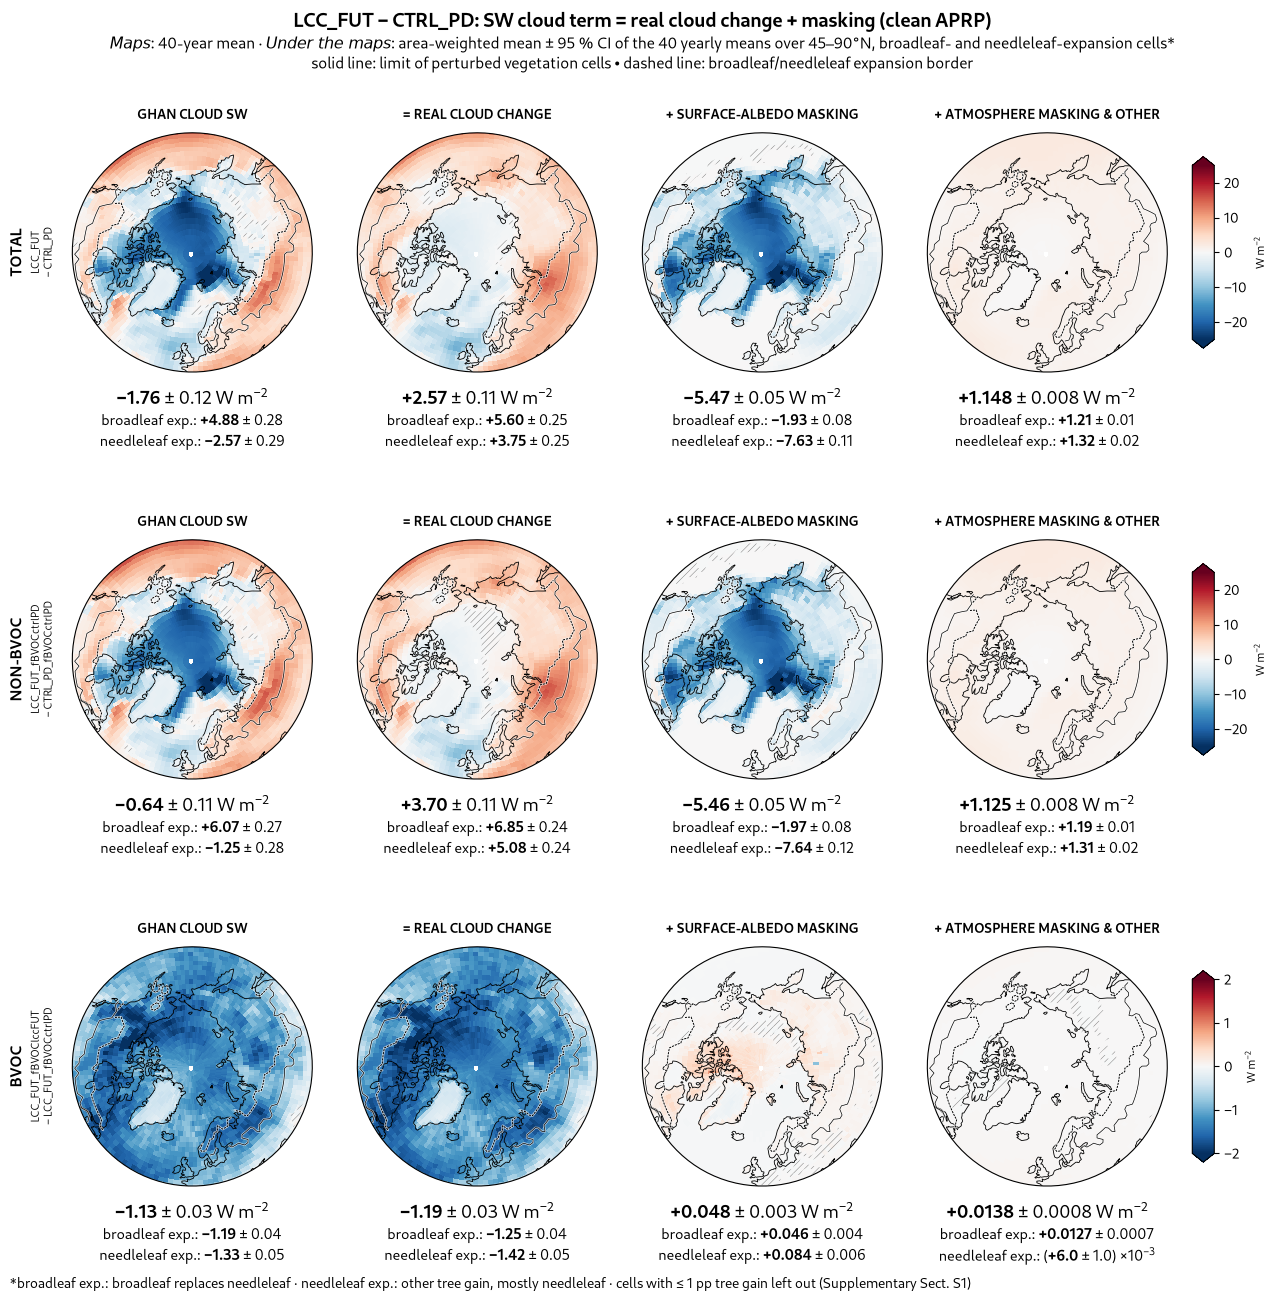

Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOCctrlPD_aprp_split_SW_2001_2040.png


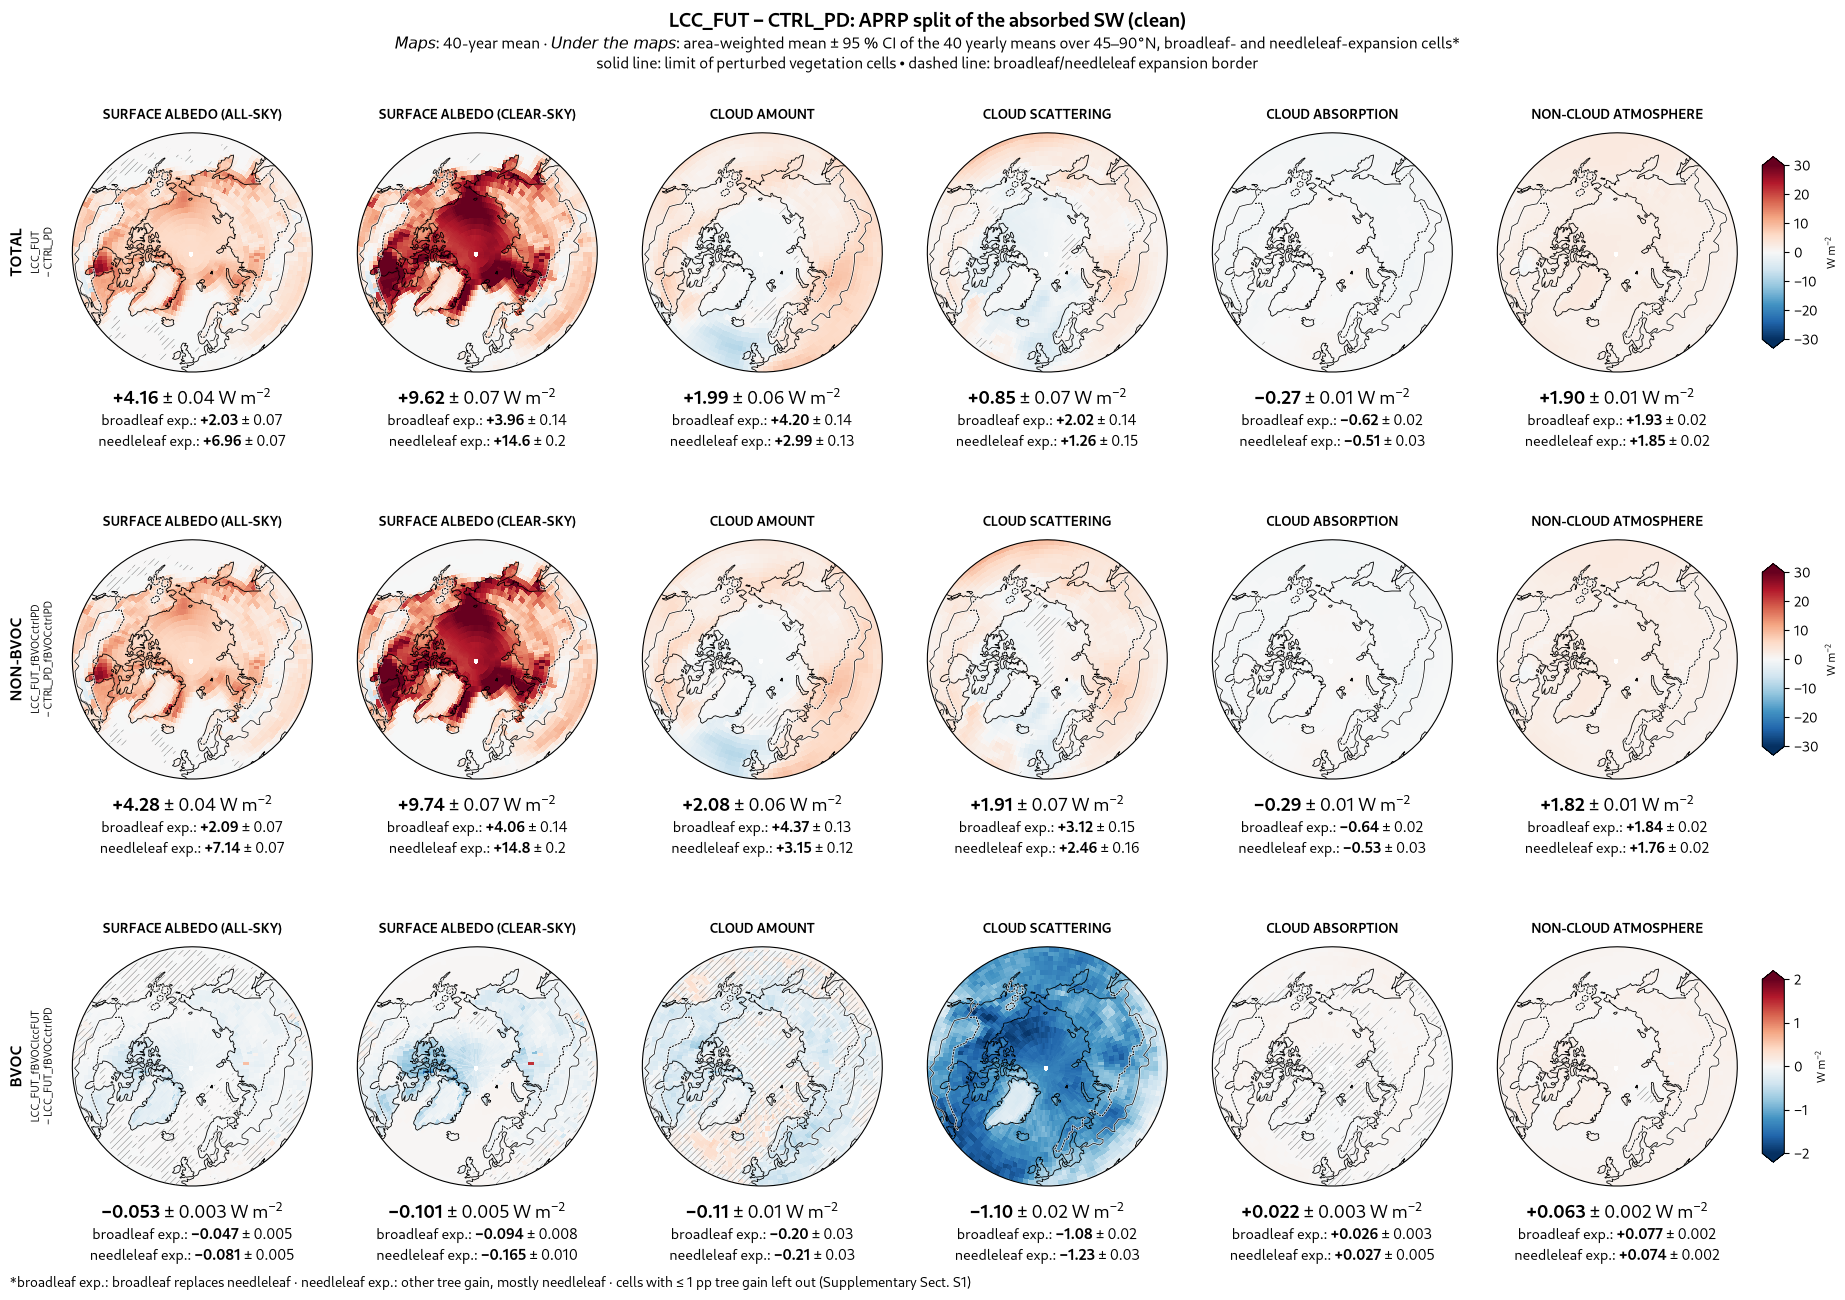

In [5]:
NICE = np.array([1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10])


def nice(v):
    k = 10.0 ** np.floor(np.log10(v))
    return float(NICE[np.searchsorted(NICE, v / k * 0.999)] * k)


def q98(ds_list, keys):
    vals = np.concatenate([np.abs(ds[k].mean("year").where(ds["lat"] >= LAT_MIN).values).ravel() for ds, k in zip(ds_list, keys)])
    return float(np.nanquantile(vals, 0.98))


def row_figure(tag, columns, fname, title):
    # columns: [(key, title)]; rows T, N, B of case `tag`; one colour scale per row
    case = CASES[tag]
    ncol = len(columns)
    fig, grid = fm.map_grid(3, ncol, under=0.75 + fm.REGION_SPACE, titles_every_row=True, left=1.15, right=1.6)
    H, W = fig.get_figheight(), fig.get_figwidth()
    for r, b in enumerate("TNB"):
        ds = APRP[(case[b], "clean")]
        vmax = nice(q98([ds] * ncol, [k for k, _ in columns]))
        for j, (k, t) in enumerate(columns):
            panel = fm.MapPanel(key=k, title=t, variable_class="RADIATIVE", variable=k, case1_role="", case2_role="")
            fm._plot_panel(grid[r, j], panel, {}, Y0, Y1, LAT_MIN, LAT_MIN, True, 0.10, vmax=vmax, d=ds[k],
                           cmap="RdBu_r", add_cbar=False)
        sm = plt.cm.ScalarMappable(norm=mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax), cmap="RdBu_r")
        fm._cbar_right(fig, grid[r], sm, "W m$^{-2}$")
        bx = grid[r, 0].get_position()
        fig.text(bx.x0 - 0.55 / W, (bx.y0 + bx.y1) / 2, BRANCH[b], rotation=90, ha="center", va="center",
                 fontsize=11, fontweight="semibold")
        fig.text(bx.x0 - 0.3 / W, (bx.y0 + bx.y1) / 2, f"{case[b][0]}\n− {case[b][1]}", rotation=90,
                 ha="center", va="center", fontsize=7.5)
    fm.add_suptitle(fig, f"{case['title']}: {title}", LAT_MIN, y=fm._suptitle_y(fig), years=Y1 - Y0 + 1)
    path = FIGDIR / f"{tag}_{fname}_{Y0}_{Y1}.png"
    fm.add_region_footnote(fig)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print("Saved", path.relative_to(REPO))
    return fig


MASK_COLS = [("ghan_cloud", "GHAN CLOUD SW"), ("cloud", "= REAL CLOUD CHANGE"),
             ("mask_sfc", "+ SURFACE-ALBEDO MASKING"), ("mask_atm_other", "+ ATMOSPHERE MASKING & OTHER")]
SPLIT_COLS = [("sfc_all", "SURFACE ALBEDO (ALL-SKY)"), ("sfc_clr", "SURFACE ALBEDO (CLEAR-SKY)"),
              ("cld_amt", "CLOUD AMOUNT"), ("cld_scat", "CLOUD SCATTERING"), ("cld_abs", "CLOUD ABSORPTION"),
              ("atm_all", "NON-CLOUD ATMOSPHERE")]
for tag in CASES:
    fig = row_figure(tag, MASK_COLS, "cloud_masking_SW", "SW cloud term = real cloud change + masking (clean APRP)")
    if tag == "LCCFUT_fBVOCctrlPD":
        plt.show()
    plt.close(fig)
    fig = row_figure(tag, SPLIT_COLS, "aprp_split_SW", "APRP split of the absorbed SW (clean)")
    if tag == "LCCFUT_fBVOCctrlPD":
        plt.show()
    plt.close(fig)

## 4. Look at the clouds themselves

Yearly differences of the cloud variables (CLOUDPROP files) for the same pairs, next to the Ghan SW cloud term and the APRP real cloud change. Each map has its own scale (the variables differ). Cloud fraction in percentage points; liquid and ice water path in g m⁻²; column droplet number CDNUMC in 10¹⁰ m⁻²; cloud-top droplet effective radius in-cloud (ACTREL / FCTL) in µm.

If a cloud term is real, the cloud variables change where it changes: less cloud (CLDTOT, CLDLOW ↓) → cloud amount term > 0; more droplets / smaller radius or more liquid water → scattering term < 0. Masking has no counterpart in the cloud variables.

Saved results/figures/cloud-masking-aprp/LCCPD_fBVOCctrlPD_cloud_variables_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOCctrlFUT_cloud_variables_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOClccPD_cloud_variables_2001_2040.png
Saved results/figures/cloud-masking-aprp/LCCFUT_fBVOCctrlPD_cloud_variables_2001_2040.png


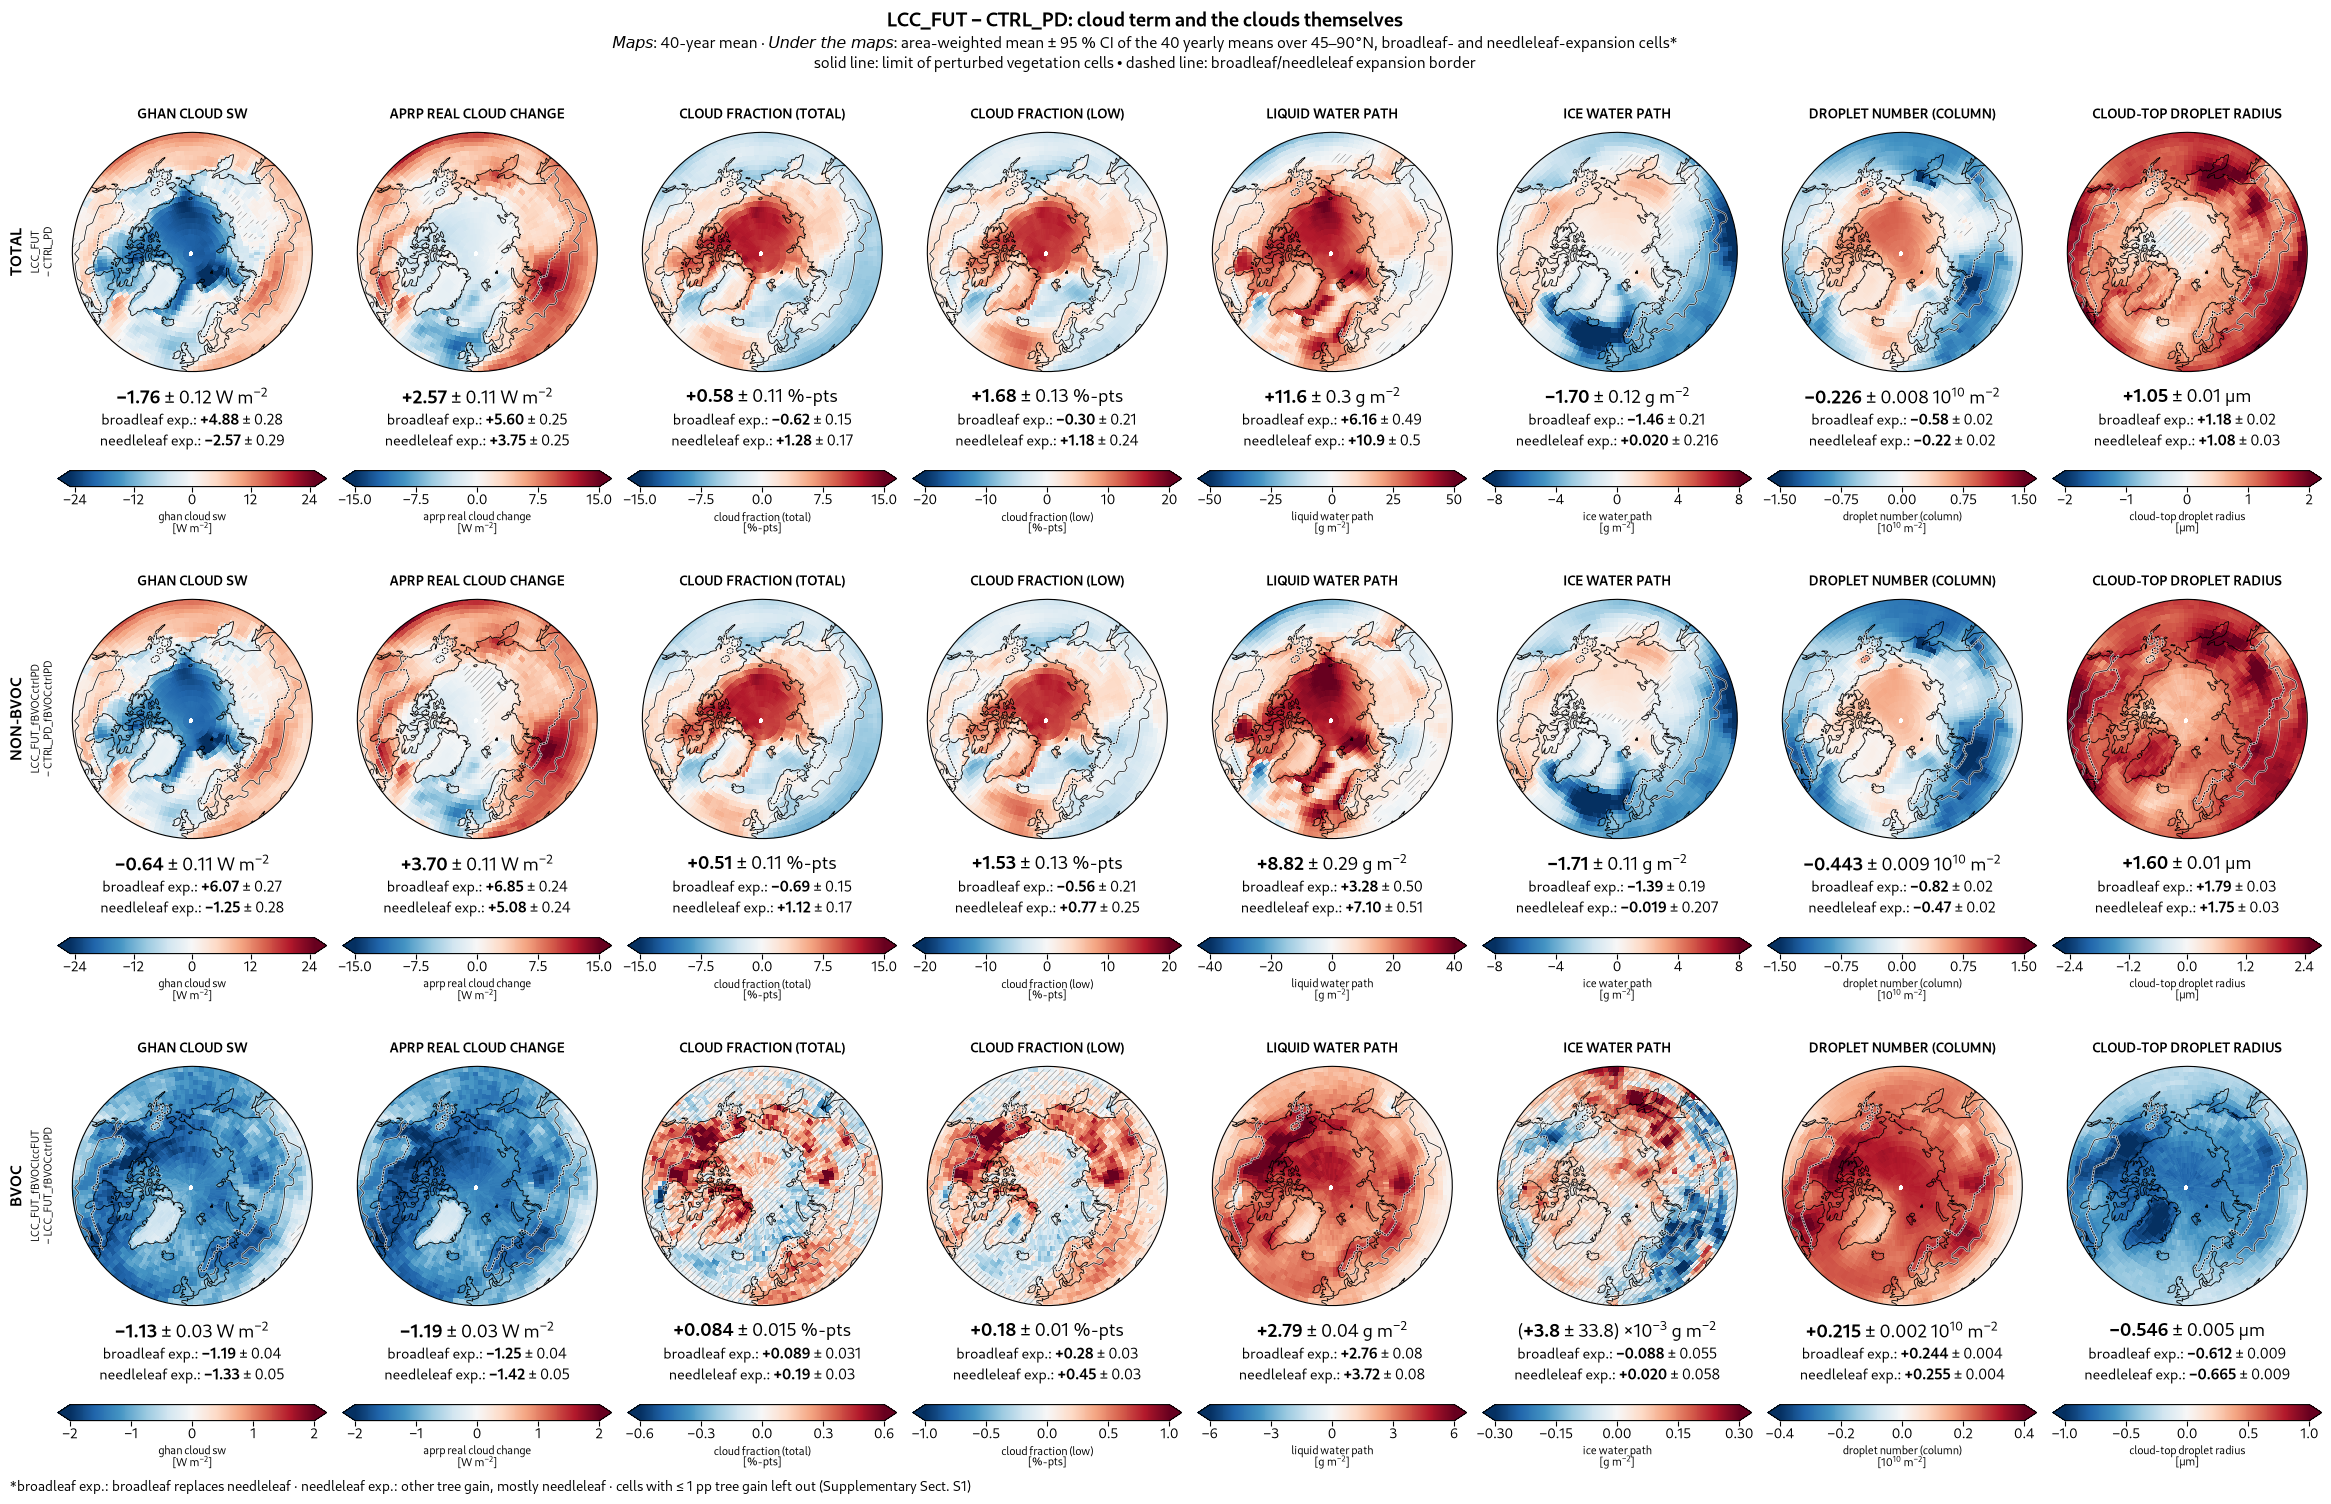

In [6]:
CLOUD_VARS = {   # key: (title, CLOUDPROP variable or YEARLY_DERIVED key, scale, units)
    "CLDTOT": ("CLOUD FRACTION (TOTAL)", "CLDTOT", 100, "%-pts"),
    "CLDLOW": ("CLOUD FRACTION (LOW)", "CLDLOW", 100, "%-pts"),
    "LWP": ("LIQUID WATER PATH", "TGCLDLWP_gm2", 1, "g m$^{-2}$"),
    "IWP": ("ICE WATER PATH", "TGCLDIWP_gm2", 1, "g m$^{-2}$"),
    "CDNUMC": ("DROPLET NUMBER (COLUMN)", "CDNUMC", 1e-10, "10$^{10}$ m$^{-2}$"),
    "REL": ("CLOUD-TOP DROPLET RADIUS", "ACTREL_incld", 1, "µm"),
}


def cloud_pair(case1, case2):
    path = CACHE / f"{case1}__{case2}_cloudvars_{Y0}_{Y1}.nc"
    if path.exists() and not REBUILD_CACHE:
        return xr.load_dataset(path)
    for attempt in range(1, 6):
        try:
            ds = xr.Dataset({k: fm.yearly_difference(case1, case2, "CLOUDPROP", v, Y0, Y1).load().drop_attrs() * s
                             for k, (_, v, s, _) in CLOUD_VARS.items()})
            break
        except (RuntimeError, OSError) as exc:
            print(f"{case1} − {case2}: read failed ({attempt}/5): {exc}")
            if attempt == 5:
                raise
            time.sleep(20 * attempt)
    ds.astype("float32").to_netcdf(path.with_suffix(".tmp"))
    path.with_suffix(".tmp").rename(path)
    return ds


CLOUDS = {p: cloud_pair(*p) for p in PAIRS}


def cloud_figure(tag):
    case = CASES[tag]
    cols = [("ghan_cloud", "GHAN CLOUD SW", "W m$^{-2}$"), ("cloud", "APRP REAL CLOUD CHANGE", "W m$^{-2}$")] + \
           [(k, t, u) for k, (t, _, _, u) in CLOUD_VARS.items()]
    fig, grid = fm.map_grid(3, len(cols), titles_every_row=True, left=1.15)
    W = fig.get_figwidth()
    for r, b in enumerate("TNB"):
        a, c = APRP[(case[b], "clean")], CLOUDS[case[b]]
        for j, (k, t, u) in enumerate(cols):
            d = a[k] if k in a else c[k]
            vmax = nice(max(fm.symmetric_vmax(d.mean("year").where(d["lat"] >= LAT_MIN)), 1e-6))
            panel = fm.MapPanel(key=k, title=t, variable_class="CLOUDPROP", variable=k, case1_role="", case2_role="",
                                units=u, long_label=t.lower())
            fm._plot_panel(grid[r, j], panel, {}, Y0, Y1, LAT_MIN, LAT_MIN, True, 0.10, vmax=vmax, d=d, cmap="RdBu_r")
        bx = grid[r, 0].get_position()
        fig.text(bx.x0 - 0.55 / W, (bx.y0 + bx.y1) / 2, BRANCH[b], rotation=90, ha="center", va="center",
                 fontsize=11, fontweight="semibold")
        fig.text(bx.x0 - 0.3 / W, (bx.y0 + bx.y1) / 2, f"{case[b][0]}\n− {case[b][1]}", rotation=90,
                 ha="center", va="center", fontsize=7.5)
    fm.add_suptitle(fig, f"{case['title']}: cloud term and the clouds themselves", LAT_MIN, y=fm._suptitle_y(fig),
                    years=Y1 - Y0 + 1)
    path = FIGDIR / f"{tag}_cloud_variables_{Y0}_{Y1}.png"
    fm.add_region_footnote(fig)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print("Saved", path.relative_to(REPO))
    return fig


for tag in CASES:
    fig = cloud_figure(tag)
    if tag == "LCCFUT_fBVOCctrlPD":
        plt.show()
    plt.close(fig)

### Spatial correlations (≥45°N, area-weighted, 25-year mean maps)

Does the Ghan cloud term follow the clouds or the masking? And do the APRP cloud terms follow the cloud variables they should (a check of APRP)? r of the maps over all cells ≥45°N (cos-lat weights).

In [7]:
def wcorr(x, y):
    x, y = x.where(x["lat"] >= LAT_MIN), y.where(y["lat"] >= LAT_MIN)
    w = np.cos(np.deg2rad(x["lat"])) * xr.ones_like(x)
    ok = np.isfinite(x) & np.isfinite(y)
    w, x, y = w.where(ok, 0), x.where(ok, 0), y.where(ok, 0)
    mx, my = (w * x).sum() / w.sum(), (w * y).sum() / w.sum()
    cov = (w * (x - mx) * (y - my)).sum()
    return float(cov / np.sqrt((w * (x - mx) ** 2).sum() * (w * (y - my) ** 2).sum()))


PAIRS_R = [("ghan_cloud", "cloud"), ("ghan_cloud", "mask_sfc"), ("ghan_cloud", "CLDTOT"), ("ghan_cloud", "LWP"),
           ("mask_sfc", "sfc_clr"), ("cld_amt", "CLDTOT"), ("cld_scat", "LWP"), ("cld_scat", "CDNUMC"), ("cld_scat", "REL")]
rows = []
for tag, case in CASES.items():
    for b in "TNB":
        both = xr.merge([APRP[(case[b], "clean")], CLOUDS[case[b]]]).mean("year")
        rows.append(dict(case=tag, branch=BRANCH[b], **{f"r({x}, {y})": wcorr(both[x], both[y]) for x, y in PAIRS_R}))
corr = pd.DataFrame(rows)
corr.to_csv(TABDIR / f"cloud_term_spatial_correlations_{Y0}_{Y1}.csv", index=False)
corr.set_index(["case", "branch"]).round(2)

r(ghan_cloud, cloud)  r(ghan_cloud, mask_sfc)  r(ghan_cloud, CLDTOT)  r(ghan_cloud, LWP)  r(mask_sfc, sfc_clr)  r(cld_amt, CLDTOT)  r(cld_scat, LWP)  r(cld_scat, CDNUMC)  r(cld_scat, REL)
case                branch                                                                                                                                                                                               
LCCPD_fBVOCctrlPD   TOTAL                    -0.01                     0.97                  -0.24               -0.53                 -0.99               -0.85             -0.49                -0.39             -0.04
                    NON-BVOC                 -0.08                     0.97                  -0.23               -0.46                 -0.99               -0.87             -0.52                -0.50             -0.03
                    BVOC                      0.93                     0.20                  -0.49               -0.45                 -0.95               -0.79             -0.42                -0.46              0.21
LCCFUT_fBVOCctrlFUT TOTAL                     0.19                     0.96                  -0.38               -0.68                 -0.99               -0.85             -0.51                -0.48              0.00
                    NON-BVOC                  0.08                     0.96                  -0.42               -0.58                 -0.99               -0.86             -0.49                -0.55              0.14
                    BVOC                      0.98                    -0.02                  -0.46               -0.66                 -0.94               -0.74             -0.67                -0.71              0.55
LCCFUT_fBVOClccPD   TOTAL                     0.66                     0.85                  -0.80               -0.89                 -0.97               -0.58             -0.80                -0.79              0.51
                    NON-BVOC                  0.66                     0.85                  -0.79               -0.88                 -0.97               -0.58             -0.78                -0.78              0.40
                    BVOC                      0.97                     0.02                  -0.16               -0.72                 -0.96               -0.75             -0.71                -0.80              0.29
LCCFUT_fBVOCctrlPD  TOTAL                     0.67                     0.86                  -0.80               -0.89                 -0.97               -0.59             -0.81                -0.79              0.52
                    NON-BVOC                  0.66                     0.85                  -0.80               -0.88                 -0.97               -0.59             -0.79                -0.78              0.41
                    BVOC                      0.97                    -0.03                  -0.20               -0.74                 -0.96               -0.76             -0.73                -0.82              0.35

## 5. Findings (run 2026-11-24, 2001–2025, clean APRP, W m⁻²; tables §3, §4)

**Checks (a).** The clean APRP cloud term reproduces the Ghan SW cloud term: ≥45°N means agree within 0.004 W m⁻², single cells within 0.01. APRP residual ≤ 0.023 W m⁻² (< 0.3 % of the change of absorbed SW); the clear-sky inversion is exact. All-sky APRP differs from Ghan by up to 3 W m⁻² in single cells (it contains aerosols), so only the clean version is used for the split.

**1. Non-BVOC and total: the negative Ghan cloud term is masking, the clouds themselves reflect less (a).**

| ≥45°N | Ghan cloud SW | = real cloud change | (amount, scattering, absorption) | + sfc-albedo masking | + atm masking & other |
|---|---|---|---|---|---|
| [LCC − CTRL]_PD, non-BVOC | −0.07 ± 0.03 | +0.16 ± 0.03 | +0.06, +0.11, −0.01 | −0.23 ± 0.01 | +0.00 |
| [LCC − CTRL]_FUT, non-BVOC | −0.02 ± 0.04 | +0.15 ± 0.03 | +0.06, +0.10, −0.01 | −0.17 ± 0.01 | +0.00 |
| LCC_FUT − CTRL_PD, non-BVOC | −0.63 ± 0.15 | +3.72 ± 0.15 | +2.07, +1.93, −0.29 | −5.47 ± 0.06 | +1.13 |

Over the modified cells ([LCC − CTRL]_PD non-BVOC): Ghan −0.26 = real +0.28 − masking 0.55. Masking ≈ −0.5 × the clear-sky surface-albedo effect (PD: −0.23 vs +0.44; maps r(mask_sfc, sfc_clr) = −0.99); the all-sky albedo effect is half the clear-sky one (+0.21 vs +0.44). The map of the Ghan cloud term follows the masking (r = 0.95–0.97 in PD and FUT) and not the real cloud change (r ≈ 0).

**2. BVOC: no masking, the Ghan cloud term is a real cloud change (a).** Masking +0.01 to +0.05 W m⁻²; Ghan ≈ real cloud change, almost all cloud scattering (brighter clouds): −0.02 PD, −0.06 FUT, −1.12 FUT with PD emissions (scattering −1.09). r(Ghan cloud, real cloud change) = 0.93–0.98.

**3. The clouds themselves agree with APRP (a).** Cloud-amount term vs ΔCLDTOT r = −0.58 to −0.86 (less cloud → more SW absorbed); scattering term vs ΔLWP r = −0.36 to −0.81 and vs Δ droplet number r = −0.36 to −0.81.

**Interpretation (b).** In the land-cover (non-BVOC) part the clouds over the boreal region become slightly fewer and thinner, which warms (+0.16 PD); the Ghan cloud term shows the opposite sign only because clouds hide part of the darker surface. Reading the Ghan cloud term as "clouds cool" is wrong for the non-BVOC branch; it is right for the BVOC branch. The atmosphere masking (+1.1, climate cases only) is the clear-sky non-cloud atmosphere change (more water vapour absorbing SW) seen less under clouds. LW masking (temperature, CO₂, water vapour) is not quantified here (needs kernels).

**Climate cases: more cloud but a positive cloud-amount term (a for numbers, b for the reason).** In LCC_FUT − CTRL_PD (non-BVOC) total cloud fraction rises (+0.55 %-pts ≥45°N, mostly over the Arctic Ocean, low clouds +1.56) while the cloud-amount term is +2.07 W m⁻². APRP weights each cloud change by insolation and by the contrast with the surface below: the cloud increase sits over sea ice and the polar night (little SW, bright surface), the decrease over sunlit land, so the decrease dominates the SW (b). The scattering term (+1.93) matches larger cloud-top droplets (+1.60 µm) and fewer droplets (−0.44 × 10¹⁰ m⁻²) in the future climate.